# Overbooking Cost Function and "No Sale" Pricing DP

This notebook computes the expected overbooking cost on departure day, solves the pricing
dynamic program with an option to stop selling coach tickets on any day, and compares that
policy with the best hard-cap overbooking policy.

## Setup: imports and parameters
*Change numbers only in the parameters cell.*

In [54]:
import numpy as np
from scipy.stats import binom
import matplotlib.pyplot as plt

In [55]:
# ===== PARAMETERS (change only here) =====
T = 365                      # days until departure

# Capacity
coach_seats = 100
fc_seats = 20

# Prices (two options per class)
coach_prices = [300, 350]
fc_prices = [425, 500]

# Daily sale probability for each price (same order as prices)
coach_probs = [0.65, 0.30]
fc_probs = [0.08, 0.04]
coach_bump_when_fc_full = 0.03   # +3 points when first class is sold out

# Show-up probabilities
coach_show = 0.95
fc_show = 0.97

# Overbooking costs
cost_upgrade = 50     # coach passenger moved to first class
cost_bump = 425       # coach passenger denied boarding

# Overbooking policies
overbook_limits = range(5, 16)   # hard cap: oversell coach by 5..15
max_coach_step3 = 120            # "no sale" policy: hard cap on coach tickets

# Discounting
annual_rate = 0.17
delta = 1 / (1 + annual_rate / 365)  # daily discount factor

## Overbooking cost function
*Used as the departure-day boundary condition by every pricing DP.*

On departure day there is no revenue, only overbooking costs. Each ticket holder shows up
independently, so the number of passengers who show up in each class is binomial:

- coach show-ups ~ Binomial(coach_sold, coach_show)
- first-class show-ups ~ Binomial(fc_sold, fc_show)

If more coach passengers show up than there are coach seats, the extra passengers are first
moved up into any empty first-class seats (`cost_upgrade` each). Anyone still without a seat
is denied boarding (`cost_bump` each). The expected cost is the probability-weighted sum over
every pair of (coach show-ups, first-class show-ups).

In [56]:
# Expected departure-day overbooking cost
def terminal_cost(coach_sold, fc_sold):
    """Expected overbooking cost on departure day, given tickets sold in each class."""
    # Probability of each possible number of show-ups (0..sold) in each class
    coach_k = np.arange(coach_sold + 1)
    fc_k = np.arange(fc_sold + 1)
    p_coach = binom.pmf(coach_k, coach_sold, coach_show)
    p_fc = binom.pmf(fc_k, fc_sold, fc_show)

    # Grid over every outcome pair: rows = coach show-ups, columns = first-class show-ups
    overflow = np.maximum(coach_k - coach_seats, 0)[:, None]   # coach passengers without a coach seat
    empty_fc = (fc_seats - fc_k)[None, :]                      # open first-class seats

    upgraded = np.minimum(overflow, empty_fc)   # moved up to first class
    bumped = overflow - upgraded                # denied boarding
    cost = cost_upgrade * upgraded + cost_bump * bumped

    # Joint probability is the product, since the two classes are independent
    return float(p_coach @ cost @ p_fc)

In [57]:
# Sanity checks: no cost without overselling; cost rises with coach sales;
# empty first-class seats make overselling cheaper (upgrades instead of bumps)
print("terminal_cost(100, 20) =", terminal_cost(coach_seats, fc_seats))
print("terminal_cost(110, 20) =", round(terminal_cost(coach_seats + 10, fc_seats), 2))
print("terminal_cost(110, 15) =", round(terminal_cost(coach_seats + 10, fc_seats - 5), 2))
print("terminal_cost(120, 20) =", round(terminal_cost(coach_seats + 20, fc_seats), 2))

terminal_cost(100, 20) = 0.0
terminal_cost(110, 20) = 1717.69
terminal_cost(110, 15) = 419.05
terminal_cost(120, 20) = 5725.0


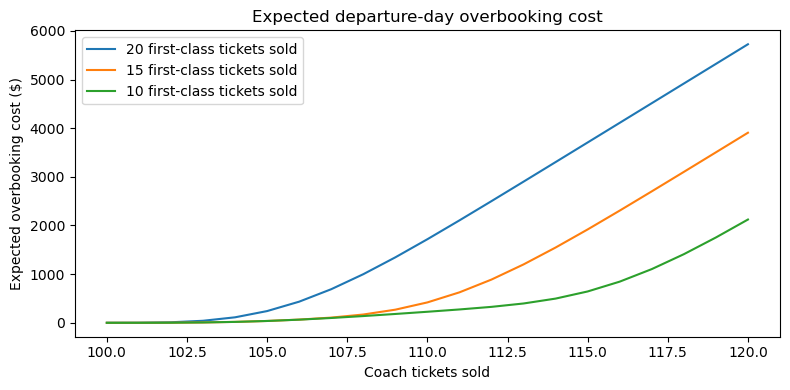

In [58]:
# Expected overbooking cost as coach sales grow (first class full vs. partly empty)
coach_range = np.arange(coach_seats, max_coach_step3 + 1)
fig, ax = plt.subplots(figsize=(8, 4))
for f in [fc_seats, fc_seats - 5, fc_seats - 10]:
    ax.plot(coach_range, [terminal_cost(c, f) for c in coach_range], label=f"{f} first-class tickets sold")
ax.set_xlabel("Coach tickets sold")
ax.set_ylabel("Expected overbooking cost ($)")
ax.set_title("Expected departure-day overbooking cost")
ax.legend()
plt.tight_layout()
plt.show()

## Pricing dynamic program

**State:** (day t, coach tickets sold c, first-class tickets sold f)

**Decision each day:** a coach option (low price, high price, or, when allowed, no sale) and a
first-class price (low or high).

**Transitions:** at most one coach sale and one first-class sale per day, independent of each other.
- First class can't sell once f = `fc_seats`; coach can't sell once c reaches the coach cap.
- When first class is sold out, the coach sale probability rises by `coach_bump_when_fc_full`
  (only on days coach is actually on sale; "no sale" stays at 0).

**Bellman equation** (revenue is earned on the day of the sale; the future is discounted by δ):

$$
V_t(c,f) = \max_{\text{coach},\,\text{FC}} \Big[\, p_c p_f\,(r_c + r_f + \delta V_{t+1}(c{+}1,f{+}1))
+ p_c(1-p_f)\,(r_c + \delta V_{t+1}(c{+}1,f))
+ (1-p_c)p_f\,(r_f + \delta V_{t+1}(c,f{+}1))
+ (1-p_c)(1-p_f)\,\delta V_{t+1}(c,f) \Big]
$$

**Boundary condition:** $V_T(c,f) = -\text{terminal\_cost}(c,f)$

The same function solves both policy types:
- **Hard cap:** `allow_no_sale=False`, `coach_cap = coach_seats + limit`
- **No-sale option:** `allow_no_sale=True`, `coach_cap = max_coach_step3`

In [59]:
# DP solver for both hard-cap and no-sale policies
def solve_dp(coach_cap, allow_no_sale):
    """
    Solve the pricing DP by backward induction.

    Returns
    -------
    V            : array (T+1, coach_cap+1, fc_seats+1), expected discounted profit-to-go
    coach_policy : array (T, coach_cap+1, fc_seats+1), coach price to charge (0 = no sale)
    fc_policy    : array (T, coach_cap+1, fc_seats+1), first-class price to charge
    """
    C, F = coach_cap, fc_seats
    c_idx = np.arange(C + 1)[:, None]   # column vector of coach-sold states
    f_idx = np.arange(F + 1)[None, :]   # row vector of first-class-sold states

    coach_open = (c_idx < C)            # coach can still sell
    fc_open = (f_idx < F)               # first class can still sell
    fc_full = ~fc_open

    # Coach options as (price, base probability); (0, 0) is "no sale"
    coach_options = list(zip(coach_prices, coach_probs))
    if allow_no_sale:
        coach_options.append((0, 0.0))
    fc_options = list(zip(fc_prices, fc_probs))

    # Sale probabilities in every state for each (coach, first-class) action pair
    actions = []
    for rc, qc in coach_options:
        bump = coach_bump_when_fc_full if qc > 0 else 0.0   # +3 points only if coach is on sale
        pc = np.where(coach_open, qc + bump * fc_full, 0.0)
        for rf, qf in fc_options:
            pf = np.where(fc_open, qf, 0.0) * np.ones((C + 1, 1))
            actions.append((rc, rf, pc, pf))

    # Boundary condition: departure day has only overbooking costs
    V = np.zeros((T + 1, C + 1, F + 1))
    V[T] = -np.array([[terminal_cost(c, f) for f in range(F + 1)] for c in range(C + 1)])

    coach_policy = np.zeros((T, C + 1, F + 1))
    fc_policy = np.zeros((T, C + 1, F + 1))
    coach_price_of = np.array([a[0] for a in actions])
    fc_price_of = np.array([a[1] for a in actions])

    for t in range(T - 1, -1, -1):
        Vn = V[t + 1]
        # Tomorrow's value after each sale outcome. At a cap the shifted value is never
        # used (its probability is 0), so the edge row/column is just repeated.
        V_c = np.vstack([Vn[1:], Vn[-1:]])            # one more coach sold
        V_f = np.hstack([Vn[:, 1:], Vn[:, -1:]])      # one more first class sold
        V_cf = np.hstack([V_c[:, 1:], V_c[:, -1:]])   # one more of each

        # Expected value of every action pair, stacked along axis 0
        values = np.stack([
            pc * pf * (rc + rf + delta * V_cf)
            + pc * (1 - pf) * (rc + delta * V_c)
            + (1 - pc) * pf * (rf + delta * V_f)
            + (1 - pc) * (1 - pf) * delta * Vn
            for rc, rf, pc, pf in actions
        ])

        best = values.argmax(axis=0)
        V[t] = values.max(axis=0)
        coach_policy[t] = coach_price_of[best]
        fc_policy[t] = fc_price_of[best]

    return V, coach_policy, fc_policy

## Hard-cap policies

Coach can be oversold by a fixed number of seats, with no option to stop selling early.
The best of these is the benchmark the no-sale policy is compared against.

In [60]:
# Hard-cap profits for each overbooking limit
hardcap_profits = {}
for limit in overbook_limits:
    V_hc, _, _ = solve_dp(coach_seats + limit, allow_no_sale=False)
    hardcap_profits[limit] = V_hc[0, 0, 0]
    print(f"Oversell by {limit:2d}: expected discounted profit = ${hardcap_profits[limit]:,.2f}")

best_limit = max(hardcap_profits, key=hardcap_profits.get)
print(f"\nBest hard cap: oversell by {best_limit} -> ${hardcap_profits[best_limit]:,.2f}")

Oversell by  5: expected discounted profit = $41,886.16
Oversell by  6: expected discounted profit = $42,011.22
Oversell by  7: expected discounted profit = $42,085.54
Oversell by  8: expected discounted profit = $42,122.17
Oversell by  9: expected discounted profit = $42,134.62
Oversell by 10: expected discounted profit = $42,132.90
Oversell by 11: expected discounted profit = $42,123.67
Oversell by 12: expected discounted profit = $42,111.03
Oversell by 13: expected discounted profit = $42,097.42
Oversell by 14: expected discounted profit = $42,084.11
Oversell by 15: expected discounted profit = $42,071.74

Best hard cap: oversell by 9 -> $42,134.62


   ### Expected profit by overbooking limit
   Profit at the smallest limit considered, then the full comparison across limits. The
   marginal change column shows what each additional oversold seat adds to (or costs) expected profit.

In [61]:
# Expected discounted profit at the smallest overbooking limit considered
base_limit = overbook_limits[0]
print(f"Overselling coach by {base_limit} seats (cap of {coach_seats + base_limit} tickets): "
      f"expected discounted profit = ${hardcap_profits[base_limit]:,.2f}")

Overselling coach by 5 seats (cap of 105 tickets): expected discounted profit = $41,886.16


In [62]:
# Expected discounted profit for every hard-cap overbooking limit,
# with the marginal change from allowing one more oversold seat
import pandas as pd

hardcap_table = pd.DataFrame({
    "Coach seats oversold": list(hardcap_profits),
    "Max coach tickets": [coach_seats + l for l in hardcap_profits],
    "Expected discounted profit ($)": list(hardcap_profits.values()),
})
hardcap_table["Marginal change ($)"] = hardcap_table["Expected discounted profit ($)"].diff()

hardcap_table.style.format(
    {"Expected discounted profit ($)": "{:,.2f}", "Marginal change ($)": "{:+,.2f}"},
    na_rep="",
).hide(axis="index")

Coach seats oversold,Max coach tickets,Expected discounted profit ($),Marginal change ($)
5,105,"41,886.16",
6,106,"42,011.22",+125.06
7,107,"42,085.54",+74.32
8,108,"42,122.17",+36.63
9,109,"42,134.62",+12.46
10,110,"42,132.90",-1.72
11,111,"42,123.67",-9.23
12,112,"42,111.03",-12.64
13,113,"42,097.42",-13.61
14,114,"42,084.11",-13.31


### Why profit peaks at a moderate overbooking limit
Each extra coach ticket earns roughly \$300–\$350, but every ticket raises the chance that more
coach passengers show up than there are seats. With a 95% show-up rate, about 5 of every 100
coach ticket holders don't show, so a modest oversell mostly fills seats that would otherwise
fly empty. Empty first-class seats also absorb overflow at only \$50 per upgrade. Beyond the best
limit, the expected cost of denying boarding (\$425 per passenger) grows faster than the extra
ticket revenue, so profit declines.

In [63]:
# Re-solve the DP at the best hard cap and keep its pricing policy,
# so it can be simulated and compared against the no-sale policy
V_hc, coach_policy_hc, fc_policy_hc = solve_dp(coach_seats + best_limit, allow_no_sale=False)

## "No sale" policy

Coach can be sold at the low price, the high price, or not at all on any day, up to
`max_coach_step3` coach tickets. This lets the airline stop overselling based on both how
many tickets are sold and how many days are left.

In [64]:
# Solve the no-sale policy and compare with the best hard cap
V_ns, coach_policy_ns, fc_policy_ns = solve_dp(max_coach_step3, allow_no_sale=True)
nosale_profit = V_ns[0, 0, 0]

print(f"No-sale policy expected discounted profit:  ${nosale_profit:,.2f}")
print(f"Best hard cap (oversell by {best_limit}):            ${hardcap_profits[best_limit]:,.2f}")
print(f"Difference:                                 ${nosale_profit - hardcap_profits[best_limit]:,.2f}")

# The no-sale policy can copy any hard cap up to max_coach_step3 by choosing "no sale",
# so it should never do worse than the best hard cap
assert nosale_profit >= hardcap_profits[best_limit] - 1e-6, "No-sale policy should be at least as good"

No-sale policy expected discounted profit:  $42,139.89
Best hard cap (oversell by 9):            $42,134.62
Difference:                                 $5.27


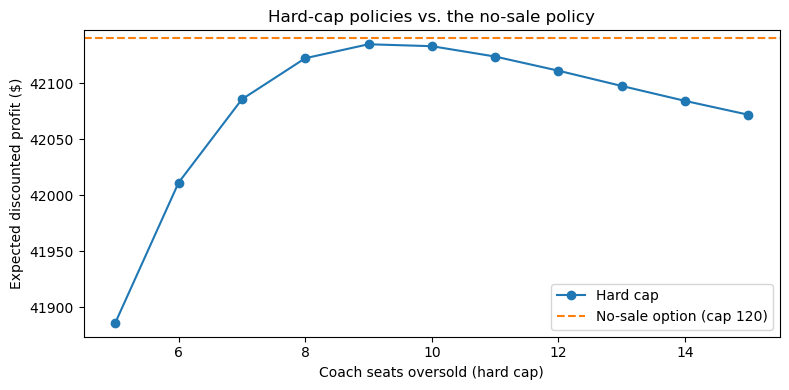

In [65]:
# Expected discounted profit: each hard cap vs. the no-sale policy
fig, ax = plt.subplots(figsize=(8, 4))
limits = list(hardcap_profits)
ax.plot(limits, [hardcap_profits[l] for l in limits], marker="o", label="Hard cap")
ax.axhline(nosale_profit, color="tab:orange", ls="--", label=f"No-sale option (cap {max_coach_step3})")
ax.set_xlabel("Coach seats oversold (hard cap)")
ax.set_ylabel("Expected discounted profit ($)")
ax.set_title("Hard-cap policies vs. the no-sale policy")
ax.legend()
plt.tight_layout()
plt.show()

## When does the no-sale policy stop selling coach?

For each day, the number of coach tickets sold at which the optimal policy switches to
"no sale". Unlike the fixed hard cap, this cutoff changes with the number of days left.

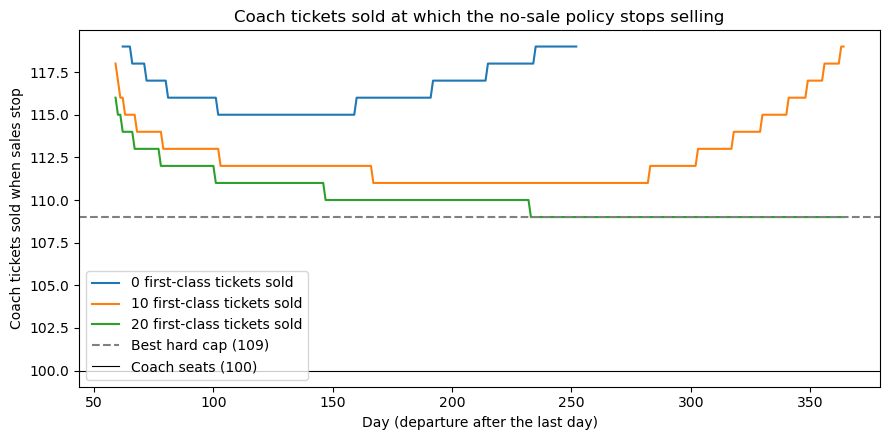

In [66]:
# Coach-sold level at which sales stop, by day
def no_sale_threshold(coach_policy, f):
    """For each day, the first coach-sold level where the policy picks 'no sale' (NaN if never)."""
    no_sale = (coach_policy[:, :, f] == 0)
    return np.where(no_sale.any(axis=1), no_sale.argmax(axis=1), np.nan)

days = np.arange(T)
fig, ax = plt.subplots(figsize=(9, 4.5))
for f in [0, fc_seats // 2, fc_seats]:
    ax.plot(days, no_sale_threshold(coach_policy_ns, f), label=f"{f} first-class tickets sold")
ax.axhline(coach_seats + best_limit, color="gray", ls="--", label=f"Best hard cap ({coach_seats + best_limit})")
ax.axhline(coach_seats, color="black", lw=0.8, label=f"Coach seats ({coach_seats})")
ax.set_xlabel("Day (departure after the last day)")
ax.set_ylabel("Coach tickets sold when sales stop")
ax.set_title("Coach tickets sold at which the no-sale policy stops selling")
ax.legend()
plt.tight_layout()
plt.show()

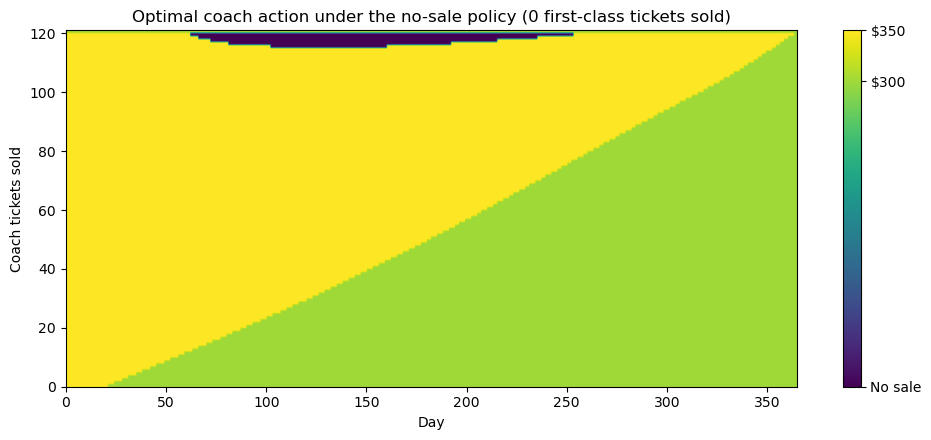

In [67]:
# Full optimal coach action by day and coach tickets sold (no first-class tickets sold yet)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(coach_policy_ns[:, :, 0].T, aspect="auto", origin="lower", cmap="viridis",
               extent=[0, T, 0, max_coach_step3 + 1])
cbar = fig.colorbar(im, ax=ax, ticks=[0] + coach_prices)
cbar.ax.set_yticklabels(["No sale"] + [f"${p}" for p in coach_prices])
ax.set_xlabel("Day")
ax.set_ylabel("Coach tickets sold")
ax.set_title("Optimal coach action under the no-sale policy (0 first-class tickets sold)")
plt.tight_layout()
plt.show()

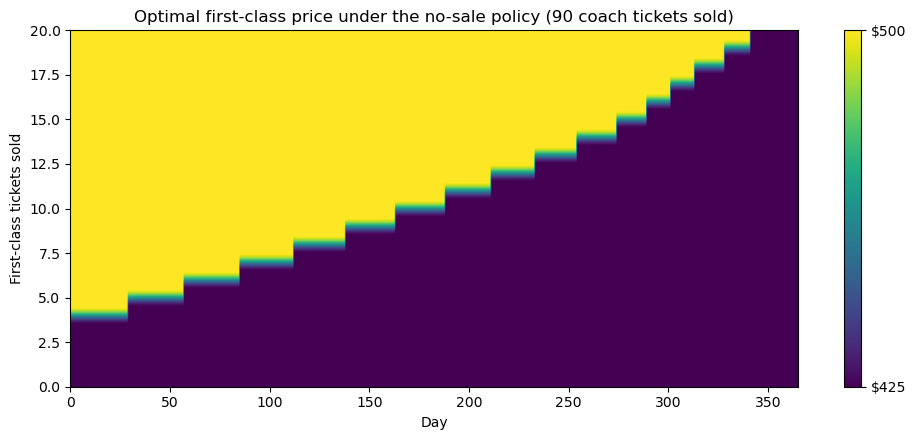

In [68]:
# Optimal first-class price by day and first-class tickets sold (coach at 90 sold, below the cap)
c_show = min(90, max_coach_step3)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(fc_policy_ns[:, c_show, :fc_seats].T, aspect="auto", origin="lower", cmap="viridis",
               extent=[0, T, 0, fc_seats], vmin=min(fc_prices), vmax=max(fc_prices))
cbar = fig.colorbar(im, ax=ax, ticks=fc_prices)
cbar.ax.set_yticklabels([f"${p}" for p in fc_prices])
ax.set_xlabel("Day")
ax.set_ylabel("First-class tickets sold")
ax.set_title(f"Optimal first-class price under the no-sale policy ({c_show} coach tickets sold)")
plt.tight_layout()
plt.show()

## Results

- `terminal_cost(coach_sold, fc_sold)`: expected departure-day overbooking cost
- `nosale_profit`: expected discounted profit of the no-sale policy
- `coach_policy_ns`, `fc_policy_ns`: the no-sale policy, as arrays indexed
  `[day, coach_sold, fc_sold]` holding the dollar price to charge (`0` = no coach sale that day)
- `hardcap_profits`, `best_limit`: hard-cap profits and the best overbooking limit

In [69]:
# Side-by-side comparison of the best hard cap and the no-sale policy
print(f"{'Policy':<40}{'Expected discounted profit':>28}")
print(f"{'Best hard cap (oversell by ' + str(best_limit) + ')':<40}{hardcap_profits[best_limit]:>28,.2f}")
print(f"{'No-sale option (cap ' + str(max_coach_step3) + ')':<40}{nosale_profit:>28,.2f}")
print(f"{'Gain from the no-sale option':<40}{nosale_profit - hardcap_profits[best_limit]:>28,.2f}")

# Example policy lookup: first selling day, nothing sold yet
print(f"\nDay 0, nothing sold: coach ${coach_policy_ns[0, 0, 0]:.0f}, first class ${fc_policy_ns[0, 0, 0]:.0f}")

Policy                                    Expected discounted profit
Best hard cap (oversell by 9)                              42,134.62
No-sale option (cap 120)                                   42,139.89
Gain from the no-sale option                                    5.27

Day 0, nothing sold: coach $350, first class $425


## Summary

The overbooking cost function finds the expected departure-day cost by summing over every
possible number of coach and first-class passengers who show up, using the binomial
distribution: coach passengers without a coach seat are moved into empty first-class seats
for \$50 each, and anyone still left over is denied boarding for \$425. The "no sale" DP adds a
third coach option each day (don't sell) with a hard cap of 120 coach tickets, so the airline
can stop selling based on both how many tickets are sold and how many days are left before
departure. With the given parameters, this policy earns an expected discounted profit of
\$42,139.89, only about \$5 more than the best hard-cap policy (overselling coach by 9 seats,
\$42,134.62), so the extra flexibility helps only slightly.